<a href="https://colab.research.google.com/github/apenkals/Spatial_Programming_2026/blob/main/Penkalski_Sketch_Five.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [129]:
%pip install -q libpysal esda splot mapclassify contextily
%pip install -q folium leafmap

In [130]:
DATA_BASE_P2 = "https://raw.githubusercontent.com/pjbitterman/KSU_x9076/main/data/part2"

import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify

tracts = gpd.read_file(f"{DATA_BASE_P2}/cuyahoga_tracts_acs.gpkg")
print(tracts.shape, tracts.crs)

column = "pct_poverty"
print(f"tracts missing for {column}:", tracts[column].isna().sum())

#land = tracts[tracts["ALAND"] > 0]
#minx, miny, maxx, maxy = land.total_bounds

(428, 13) EPSG:4269
tracts missing for pct_poverty: 7


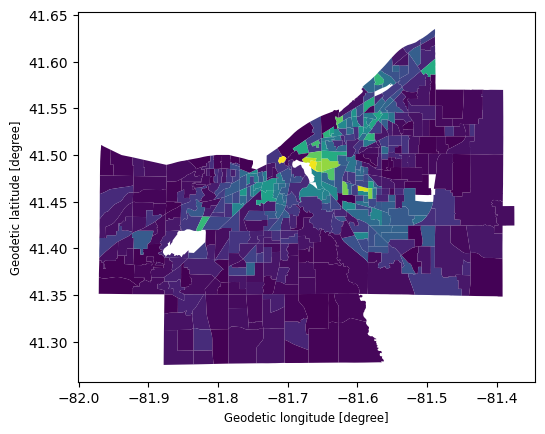

In [131]:
tracts.plot(column="pct_poverty")
plt.show()

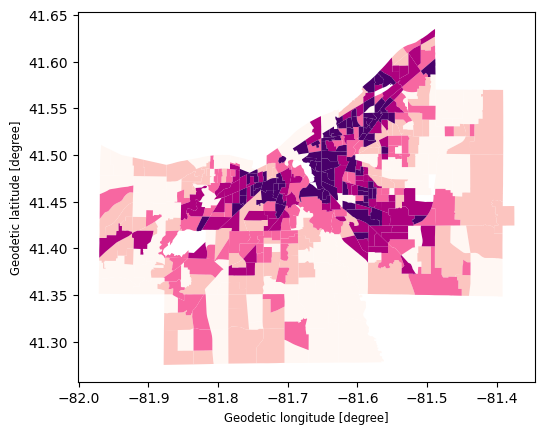

In [132]:
tracts.plot(
    column="pct_poverty",
    scheme="quantiles",   # NEW
    k=5,                  # NEW
    cmap="RdPu",        # NEW
)
plt.show()

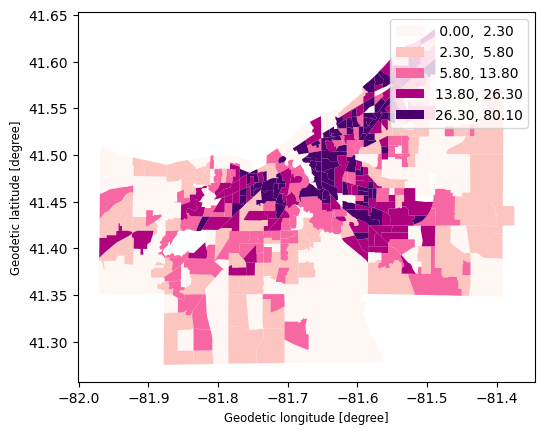

In [133]:
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="RdPu",
    legend=True,
)
plt.show()

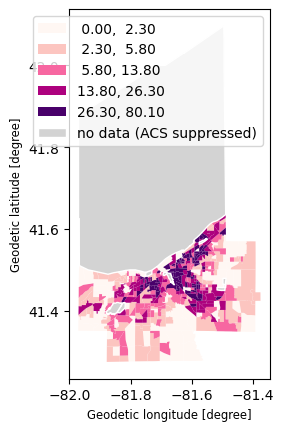

In [134]:
tracts.plot(
    column=column,
    scheme="quantiles",
    k=5,
    cmap="RdPu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white","label": "no data (ACS suppressed)"}
)
plt.show()

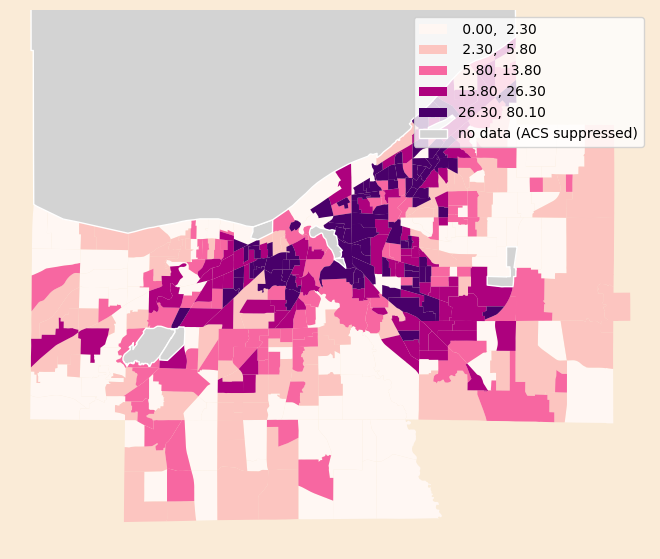

In [135]:
land = tracts[tracts["ALAND"] > 0]
minx, miny, maxx, maxy = land.total_bounds

fig, ax = plt.subplots(figsize=(9, 7), facecolor="antiquewhite")
tracts.plot(
    column="pct_poverty",
    scheme="quantiles",
    k=5,
    cmap="RdPu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    ax=ax,
)

ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
plt.show()

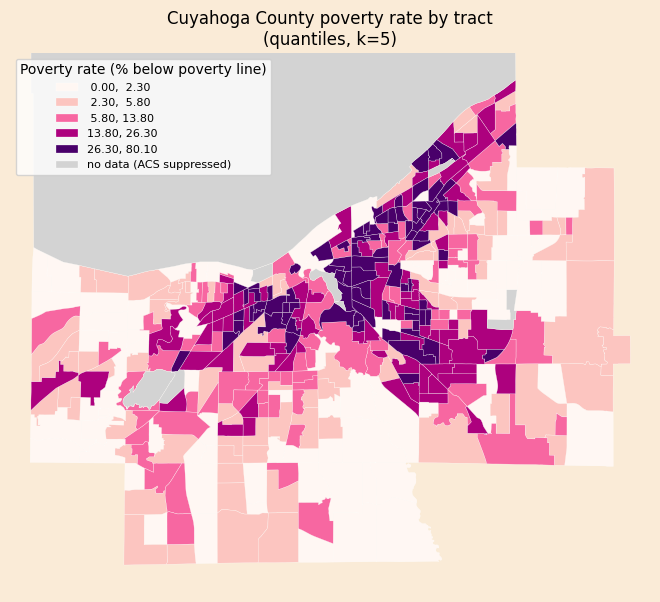

In [136]:
fig, ax = plt.subplots(figsize=(9, 7), facecolor="antiquewhite")
tracts.plot(
    column="pct_poverty",
    scheme="quantiles",
    k=5,
    cmap="RdPu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Poverty rate (% below poverty line)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County poverty rate by tract\n(quantiles, k=5)")
fig.savefig("poverty_quantiles.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

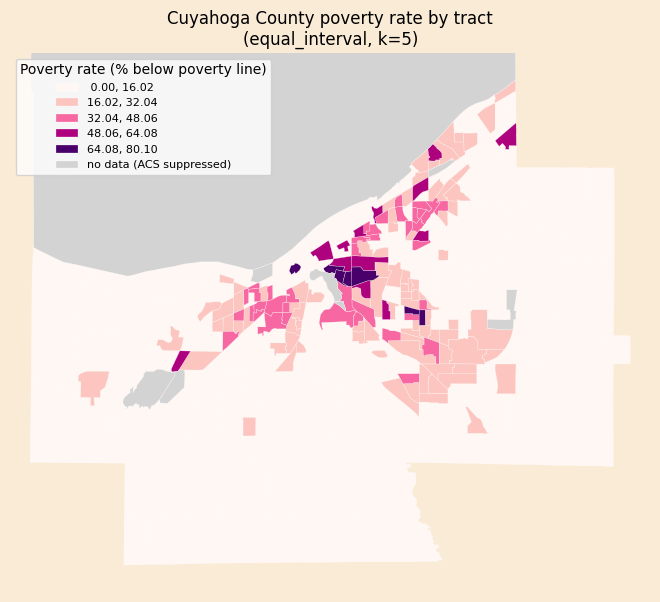

In [137]:
fig, ax = plt.subplots(figsize=(9, 7), facecolor="antiquewhite")
tracts.plot(
    column="pct_poverty",
    scheme="equal_interval",
    k=5,
    cmap="RdPu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Poverty rate (% below poverty line)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County poverty rate by tract\n(equal_interval, k=5)")
fig.savefig("poverty__equal_interval.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

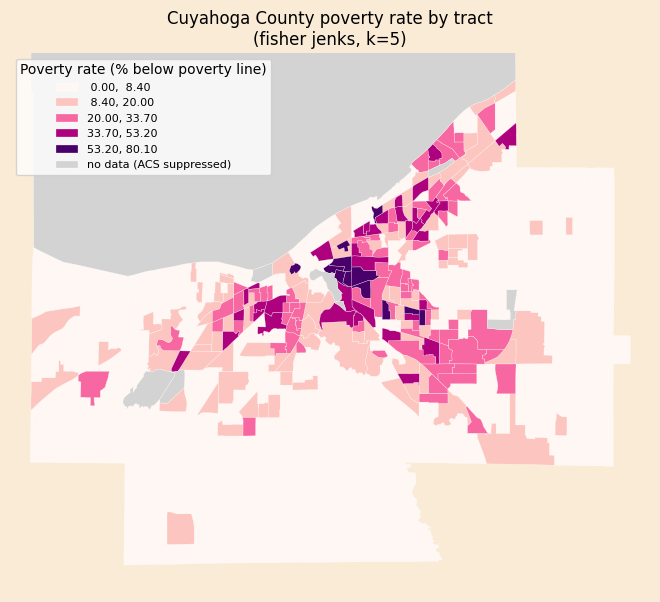

In [138]:
fig, ax = plt.subplots(figsize=(9, 7), facecolor="antiquewhite")
tracts.plot(
    column="pct_poverty",
    scheme="fisher_jenks",
    k=5,
    cmap="RdPu",
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "no data (ACS suppressed)"},
    legend_kwds={"title": "Poverty rate (% below poverty line)", "loc": "upper left", "fontsize": 8},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County poverty rate by tract\n(fisher jenks, k=5)")
fig.savefig("poverty_fisher_jenks.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

In [139]:
vals = tracts[column].dropna()
print("quantiles", mapclassify.Quantiles(vals, k=5).counts.tolist())
print("equal_interval", mapclassify.EqualInterval(vals, k=5).counts.tolist())
print("fisher_jenks", mapclassify.FisherJenks(vals, k=5).counts.tolist())

quantiles [85, 84, 84, 84, 84]
equal_interval [275, 87, 39, 13, 7]
fisher_jenks [206, 92, 75, 36, 12]


I would use fisher jenks when I want the breaks to follow where poverty rates actually jump; it keeps tracts that are similar together and still leaves enough tracts in the higher classes.

The equal interval map is the one that would likely mislead the most because its counts are 275, 87, 39, 13, and 7, which puts 275 out of 421 tracts in the lightest class. For quantile maps, the same lowest-rate tracts end up spreading across the three lightest classes and into the fourth, so a tract that reads as middle-to-high on quantiles can show up as the lightest for equal interval. Also, the darkest class holds only 7 tracts on equal int., so the two maps tell very different stories. If I just looked at the equal int. I would wrongly assume poverty is extremely low everywhere (and limited geographically). If there are a few extremes, they can stretch the value range and the equal-width bins end up becoming overtaken by them. The scheme change is also most dramatic between quantile and equal int., where the poverty rates for Cleveland change DRASTICALLY.